# Кейс №5 · Bounty runes
Проверяем, связан ли ранний сбор Bounty Rune с преимуществом по золоту и взятием первой башни. Источники — матчи и составы команд из PostgreSQL, подборы рун, золотые события и падения башен из MongoDB.
1. Основная гипотеза. Команда, собравшая ≥70% наблюдаемых Bounty Rune за первые 10 минут, чаще опережает соперника по all_gold_0_10. Это сумма gold_events.amount со знаком по команде за 0 ≤ time < 600 секунд.
2. Начисления. Проверяем, получает ли та же команда больше положительных начислений. Повторяем сравнение без начислений BOUNTY, чтобы оценить, насколько результат меняется.
3. Первая башня. Проверяем, как часто лидер по подборам до 12:00 первым сносит вражескую башню.

## Золото за первые 10 минут
По данным последнего прогона сравнить золото обеих команд удалось в 61 110 из 63 741 матчей, где одна команда гарантированно собрала ≥70% наблюдаемых рун. Из сравнения исключены 2 543 матча с золотыми событиями без определённой команды, 87 без золотых событий и один без положительных начислений у одной стороны.

| Расчёт | Пригодные матчи | Лидер по рунам впереди | Средний перевес | Медианный перевес |
|---|---:|---:|---:|---:|
| all_gold_0_10 · начисления и списания | 61 110 | 39 667 (64,91%) | +1 816,9 | +1 294 |
| Только начисления | 61 110 | 39 920 (65,32%) | +1 790,4 | +1 242 |
| Начисления без Bounty Rune | 61 110 | 33 454 (54,74%) | +730,6 | +377 |
| all_gold_0_10 · ровно 8 наблюдаемых подборов | 11 688 | 9 022 (77,19%) | +3 605,8 | +2 693 |

В пригодной выборке команда с ≥70% рун чаще опережала соперника по all_gold_0_10. Исключение прямых начислений за руны уменьшает долю лидеров по положительным начислениям на 10,58 процентного пункта. Это наблюдаемая связь.

Сравнение «5 из 8» и «6–8 из 8» использует матчи, в которых известна сторона каждого из восьми подборов. Сравниваем долю матчей с положительным перевесом и медиану по Radiant и Dire. Эта выборка может отличаться от строки «ровно 8» в таблице выше.

## Первая башня
Лидер по Bounty Rune к 12:00 взял первую вражескую башню в 84 553 из 161 102 пригодных матчей (52,5%). 95% интервал Уилсона — 52,2–52,7%. Из 314 409 матчей длительностью от 12 минут в эти 161 102 вошли матчи с однозначным лидером по рунам и известной стороной первой башни.

| Лидер по рунам | Взял первую башню | Доля |
|---|---:|---:|
| Radiant | 42 322 из 72 181 | 58,6% |
| Dire | 42 231 из 88 921 | 47,5% |

В объединённой выборке совпадение встречалось немного чаще половины. При лидере Radiant доля выше 50%, при лидере Dire — ниже. Это ограничивает общий вывод о связи лидерства по рунам с первой башней. Это наблюдаемая связь внутри матча. Лидер по рунам определяется по подборам до 12:00, а сторона первой башни определяется по первому падению за матч.

## Графики
Точки показывают доли, отрезки — 95% интервалы Уилсона. Пунктир обозначает 50%. Графики построены по сохранённым итогам успешного прогона.

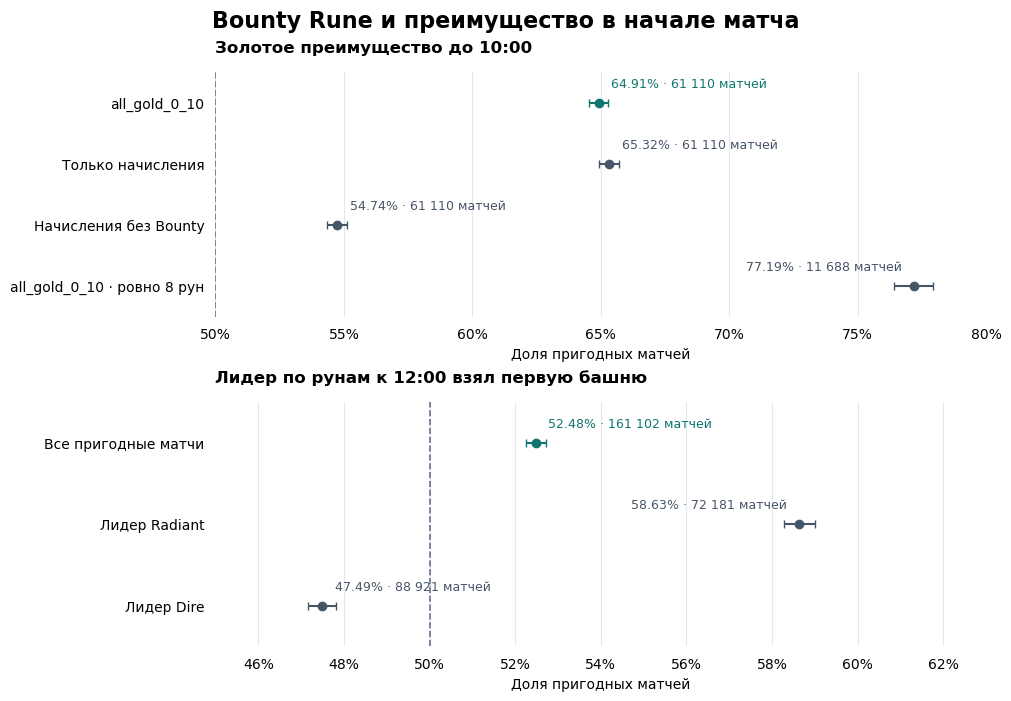

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Агрегаты успешного прогона Spark. Для графиков достаточно этих счётчиков.
chart_groups = [
    ("Золотое преимущество до 10:00", [
        ("all_gold_0_10", 39667, 61110),
        ("Только начисления", 39920, 61110),
        ("Начисления без Bounty", 33454, 61110),
        ("all_gold_0_10 · ровно 8 рун", 9022, 11688),
    ], [50, 80]),
    ("Лидер по рунам к 12:00 взял первую башню", [
        ("Все пригодные матчи", 84553, 161102),
        ("Лидер Radiant", 42322, 72181),
        ("Лидер Dire", 42231, 88921),
    ], [45, 63]),
]

fig, axes = plt.subplots(2, 1, figsize=(10, 6.9), layout="constrained")
for ax, (title, rows, limits) in zip(axes, chart_groups):
    ax.set_title(title, loc="left", weight="bold", pad=14)
    ax.set_xlim(limits)
    ax.set_ylim(len(rows) - 0.5, -0.5)
    ax.set_yticks(range(len(rows)), [label for label, _, _ in rows])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.grid(axis="x", color="#e2e8f0")
    ax.axvline(50, color="#64748b", linestyle="--", linewidth=1.2)
    ax.set_xlabel("Доля пригодных матчей")
    ax.tick_params(axis="both", length=0, pad=8)
    for spine in ax.spines.values():
        spine.set_visible(False)

    for index, (_, ahead, total) in enumerate(rows):
        share = ahead / total
        z = 1.96
        denominator = 1 + z**2 / total
        center = (share + z**2 / (2 * total)) / denominator
        half_width = z * (share * (1 - share) / total + z**2 / (4 * total**2))**0.5 / denominator
        low, high = 100 * (center - half_width), 100 * (center + half_width)
        value = 100 * share
        color = "#0f766e" if index == 0 else "#475569"
        ax.errorbar(value, index, xerr=[[value - low], [high - value]],
                    fmt="o", color=color, capsize=3, zorder=3)
        label = f"{value:.2f}% · {total:,} матчей".replace(",", " ")
        align = "right" if value >= limits[1] - (limits[1] - limits[0]) * 0.26 else "left"
        ax.annotate(label, (value, index), xytext=(-9 if align == "right" else 9, 9),
                    textcoords="offset points", ha=align, va="bottom", fontsize=9, color=color)

fig.suptitle("Bounty Rune и преимущество в начале матча", fontsize=16, weight="bold")
plt.show()


Прямоугольники показывают центральные 50% матчей, черта внутри — медиану. Это квартили из сохранённого прогона. Для гистограммы и boxplot с усами запустите ячейку «Spark · Золотые события».

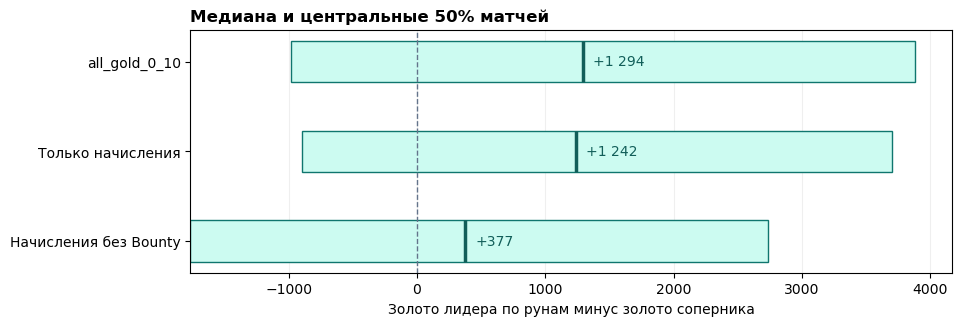

In [2]:
import matplotlib.pyplot as plt

# Квартили золотого перевеса из сохранённого прогона на 61 110 матчах.
quartiles = [
    ("all_gold_0_10", -984, 1294, 3884),
    ("Только начисления", -894, 1242, 3702),
    ("Начисления без Bounty", -1765, 377, 2734),
]
fig, ax = plt.subplots(figsize=(9.5, 3.15), layout="constrained")
for i, (label, q1, median, q3) in enumerate(quartiles):
    ax.barh(i, q3 - q1, left=q1, height=0.46, color="#ccfbf1", edgecolor="#0f766e")
    ax.vlines(median, i - 0.23, i + 0.23, color="#115e59", linewidth=2.5)
    ax.annotate(f"{median:+,}".replace(",", " "), (median, i),
                xytext=(7, 0), textcoords="offset points", va="center", color="#115e59")
ax.set_yticks(range(len(quartiles)), [row[0] for row in quartiles])
ax.invert_yaxis()
ax.axvline(0, color="#64748b", linestyle="--", linewidth=1)
ax.set_xlabel("Золото лидера по рунам минус золото соперника")
ax.set_title("Медиана и центральные 50% матчей", loc="left", weight="bold")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.show()


## Пояснение про график 
Команда с ≥70% рун опережала соперника по начислениям и списаниям в 64,91% из 61 110 пригодных матчей. Медианный перевес составил 1 294 золота. По начислениям без Bounty доля составила 54,74%. Лидер по рунам к 12:00 взял первую башню в 52,5% пригодных матчей. Для лидера Radiant это 58,6%, для лидера Dire — 47,5%.

## Проверка качества данных
| Источник | Проверено строк | Строк без валидного ключа | Повторяющихся ключей | Лишних строк | Конфликтов |
|---|---:|---:|---:|---:|---:|
| pg__matches | 317 421 | 0 | 0 | 0 | 0 |
| pg__match_players | 4 685 391 | 0 | 0 | 0 | 0 |
| mongo__rune_events | 2 222 573 | 0 | 0 | 0 | 0 |
| mongo__gold_events | 135 762 117 | 0 | 0 | 0 | 0 |
| mongo__tower_death_events | 7 699 166 | 0 | 0 | 0 | 0 |

Ключи проверки — match_id для матчей, (match_id, player_slot) для составов и (match_id, id) для событий. Матчи, составы и башни проверены за доступную историю, руны BOUNTY / PICKUP — с 0:00 до 12:00, золото — с 0:00 до 10:00. Конфликт означает, что у записей с одним ключом отличаются поля, используемые в расчёте. Покрытие сопоставления событий с командами учитывается отдельно.

Для all_gold_0_10 проверка выбросов использует границы Q1 − 1,5 × IQR и Q3 + 1,5 × IQR. По последним квартилям это −8 286 и +11 186 золота. Ячейка «Spark · Золотые события» показывает число матчей за границами и сравнивает результат на всей пригодной выборке и внутри границ. В строке «Все» matches должно совпадать с unique_match_ids.

In [3]:
from lakehouse_spark import SparkSessionContext

checks = [
    ("pg__matches", "match_id", "match_id IS NOT NULL AND match_id > 0",
     "STRUCT(duration)", "TRUE"),
    ("pg__match_players", "match_id, player_slot",
     "match_id IS NOT NULL AND match_id > 0 AND player_slot BETWEEN 0 AND 255",
     "STRUCT(account_id, is_radiant)", "TRUE"),
    ("mongo__rune_events", "match_id, id",
     "match_id IS NOT NULL AND match_id > 0 AND id IS NOT NULL AND TRIM(id) <> ''",
     "STRUCT(steam_account_id, time)",
     "rune = 'BOUNTY' AND action = 'PICKUP' AND time >= 0 AND time < 720"),
    ("mongo__gold_events", "match_id, id",
     "match_id IS NOT NULL AND match_id > 0 AND id IS NOT NULL AND TRIM(id) <> ''",
     "STRUCT(steam_account_id, time, amount, reason)", "time >= 0 AND time < 600"),
    ("mongo__tower_death_events", "match_id, id",
     "match_id IS NOT NULL AND match_id > 0 AND id IS NOT NULL AND TRIM(id) <> ''",
     "STRUCT(time, radiant, dire)", "TRUE"),
]

with SparkSessionContext("bounty-data-quality") as spark:
    report = []
    for table, keys, valid_key, fields, scope in checks:
        row = spark.sql(f"""
            WITH key_counts AS (
                SELECT ({valid_key}) AS valid_key, COUNT(*) AS rows_for_key,
                       MIN({fields}) <> MAX({fields}) AS conflicting
                FROM lakehouse.raw.{table}
                WHERE {scope}
                GROUP BY {keys}
            )
            SELECT COALESCE(SUM(rows_for_key), 0) AS rows_checked,
                   COALESCE(SUM(CASE WHEN NOT COALESCE(valid_key, FALSE)
                                     THEN rows_for_key ELSE 0 END), 0) AS rows_without_valid_key,
                   COUNT_IF(valid_key AND rows_for_key > 1) AS duplicate_keys,
                   COALESCE(SUM(CASE WHEN valid_key THEN rows_for_key - 1 ELSE 0 END), 0) AS extra_rows,
                   COUNT_IF(valid_key AND conflicting) AS conflicting_keys
            FROM key_counts
        """).first()
        report.append((table, *row))

    spark.spark.createDataFrame(
        report, "source STRING, rows_checked LONG, rows_without_valid_key LONG, "
        "duplicate_keys LONG, extra_rows LONG, conflicting_keys LONG"
    ).show(truncate=False)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/13 07:44:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

+-------------------------+------------+----------------------+--------------+----------+----------------+
|source                   |rows_checked|rows_without_valid_key|duplicate_keys|extra_rows|conflicting_keys|
+-------------------------+------------+----------------------+--------------+----------+----------------+
|pg__matches              |317478      |0                     |0             |0         |0               |
|pg__match_players        |4689391     |0                     |0             |0         |0               |
|mongo__rune_events       |2222573     |0                     |0             |0         |0               |
|mongo__gold_events       |135762117   |0                     |0             |0         |0               |
|mongo__tower_death_events|7700547     |0                     |0             |0         |0               |
+-------------------------+------------+----------------------+--------------+----------+----------------+



## Воспроизводимость расчёта
Матчи соединяем с рунами и башнями по match_id. Подборы и золотые события связываем со стороной по (match_id, account_id). У составов оставляем только однозначные пары аккаунт–слот–сторона. Доля рун использует все наблюдаемые подборы в окне, включая записи без определённой команды. Команда гарантированно проходит порог, если он выполняется даже при передаче всех неизвестных подборов сопернику.

Первую башню определяем по первой наблюдаемой секунде с одним установленным битом разрушения. Сторона потерянной башни противоположна стороне, взявшей её. При нескольких битах или пропусках исход помечается как неоднозначный.

Золото и начисления считаем за 0 ≤ time < 600 секунд, лидерство по рунам для башни — за 0 ≤ time < 720. Первую башню определяем за весь матч. До 10:00 ровно восемь подборов зарегистрированы в 76 425 матчах. При восьми подборах для порога ≥70% нужно минимум шесть.

Для гистограммы и boxplot с усами запустите ячейку «Spark · Золотые события». Она строит графики и сводку за один прогон.

In [4]:
from collections import Counter
from math import sqrt

from lakehouse_spark import SparkSessionContext


with SparkSessionContext("bounty-full-history") as spark:
    summary = spark.sql("""
        WITH matches AS (
            SELECT match_id, MIN(duration) AS duration
            FROM lakehouse.raw.pg__matches
            WHERE match_id IS NOT NULL
            GROUP BY match_id
            HAVING MIN(duration) >= 600
        ),
        teams AS (
            SELECT match_id, account_id, MIN(CAST(is_radiant AS INT)) AS side
            FROM lakehouse.raw.pg__match_players
            WHERE match_id IS NOT NULL
              AND account_id > 0 AND account_id <> 4294967295
            GROUP BY match_id, account_id
            HAVING MIN(player_slot) = MAX(player_slot)
               AND MIN(CAST(is_radiant AS INT)) = MAX(CAST(is_radiant AS INT))
               AND COUNT(player_slot) = COUNT(*)
               AND COUNT(is_radiant) = COUNT(*)
        ),
        pickups AS (
            SELECT DISTINCT match_id, id, steam_account_id, time
            FROM lakehouse.raw.mongo__rune_events
            WHERE match_id IS NOT NULL
              AND rune = 'BOUNTY' AND action = 'PICKUP'
              AND time >= 0 AND time < 720
        ),
        runes AS (
            SELECT r.match_id,
                   COUNT(CASE WHEN r.time < 600 AND t.side = 1 THEN 1 END) AS radiant_10,
                   COUNT(CASE WHEN r.time < 600 AND t.side = 0 THEN 1 END) AS dire_10,
                   COUNT(CASE WHEN r.time < 600 AND t.side IS NULL THEN 1 END) AS unknown_10,
                   COUNT(CASE WHEN t.side = 1 THEN 1 END) AS radiant_12,
                   COUNT(CASE WHEN t.side = 0 THEN 1 END) AS dire_12,
                   COUNT(CASE WHEN t.side IS NULL THEN 1 END) AS unknown_12
            FROM pickups r
            LEFT JOIN teams t
              ON r.match_id = t.match_id AND r.steam_account_id = t.account_id
            GROUP BY r.match_id
        ),
        tower_events AS (
            SELECT match_id, time, radiant, dire,
                   MIN(CASE WHEN radiant <> 0 OR dire <> 0
                              OR radiant IS NULL OR dire IS NULL THEN time END)
                       OVER (PARTITION BY match_id) AS first_time,
                   MAX(CASE WHEN time IS NULL THEN 1 ELSE 0 END)
                       OVER (PARTITION BY match_id) AS missing_time
            FROM lakehouse.raw.mongo__tower_death_events
            WHERE match_id IS NOT NULL
        ),
        first_tower AS (
            SELECT match_id, MIN(first_time) AS first_tower_time,
                   BIT_OR(radiant) AS radiant_mask, BIT_OR(dire) AS dire_mask,
                   MAX(CASE WHEN missing_time = 1 OR radiant IS NULL OR dire IS NULL
                              OR radiant < 0 OR dire < 0
                            THEN 1 ELSE 0 END) AS invalid
            FROM tower_events
            WHERE time = first_time OR time IS NULL
            GROUP BY match_id
        ),
        per_match AS (
            SELECT m.duration,
                   COALESCE(r.radiant_10, 0) AS radiant_10,
                   COALESCE(r.dire_10, 0) AS dire_10,
                   COALESCE(r.unknown_10, 0) AS unknown_10,
                   COALESCE(r.radiant_12, 0) AS radiant_12,
                   COALESCE(r.dire_12, 0) AS dire_12,
                   COALESCE(r.unknown_12, 0) AS unknown_12,
                   f.first_tower_time,
                   CASE
                       WHEN f.invalid <> 0
                         OR f.first_tower_time < 0
                         OR f.first_tower_time > m.duration THEN NULL
                       WHEN f.dire_mask = 0 AND f.radiant_mask > 0
                         AND (f.radiant_mask & (f.radiant_mask - 1)) = 0 THEN 'Dire'
                       WHEN f.radiant_mask = 0 AND f.dire_mask > 0
                         AND (f.dire_mask & (f.dire_mask - 1)) = 0 THEN 'Radiant'
                   END AS tower_side,
                   f.match_id IS NOT NULL AS has_tower_record
            FROM matches m
            LEFT JOIN runes r ON m.match_id = r.match_id
            LEFT JOIN first_tower f ON m.match_id = f.match_id
        ),
        classified AS (
            SELECT
                CASE
                    WHEN radiant_10 + dire_10 + unknown_10 = 0 THEN 'no_pickups'
                    WHEN 10 * radiant_10 >= 7 * (radiant_10 + dire_10 + unknown_10)
                        THEN 'Radiant'
                    WHEN 10 * dire_10 >= 7 * (radiant_10 + dire_10 + unknown_10)
                        THEN 'Dire'
                    WHEN 10 * (GREATEST(radiant_10, dire_10) + unknown_10)
                         < 7 * (radiant_10 + dire_10 + unknown_10)
                        THEN 'below_70'
                    ELSE 'uncertain'
                END AS threshold_10,
                unknown_10 > 0 AS partial_10,
                CASE
                    WHEN duration < 720 THEN 'short_match'
                    WHEN radiant_12 + dire_12 + unknown_12 = 0 THEN 'no_pickups'
                    WHEN radiant_12 > dire_12 + unknown_12 THEN 'Radiant'
                    WHEN dire_12 > radiant_12 + unknown_12 THEN 'Dire'
                    WHEN unknown_12 = 0 AND radiant_12 = dire_12 THEN 'tie'
                    ELSE 'uncertain'
                END AS leader_12,
                unknown_12 > 0 AS partial_12,
                CASE
                    WHEN duration < 720 THEN 'short_match'
                    WHEN NOT has_tower_record THEN 'no_tower_event'
                    WHEN tower_side IS NULL THEN 'uncertain'
                    ELSE 'known'
                END AS tower_status,
                CASE WHEN duration >= 720 THEN tower_side END AS tower_side
            FROM per_match
        )
        SELECT threshold_10, partial_10, leader_12, partial_12, tower_status, tower_side,
               COUNT(*) AS matches
        FROM classified
        GROUP BY threshold_10, partial_10, leader_12, partial_12, tower_status, tower_side
    """).collect()

threshold_counts = Counter()
leader_counts = Counter()
tower_counts = Counter()
for row in summary:
    count = row["matches"]
    threshold_counts[row["threshold_10"]] += count
    leader_counts[row["leader_12"]] += count
    tower_counts[row["tower_status"]] += count

print(f"Матчей длительностью от 10:00: {sum(threshold_counts.values())}")
print(f"Матчей длительностью от 12:00: {sum(leader_counts.values()) - leader_counts['short_match']}")
print("\n10:00 · Порог 70% среди наблюдаемых подборов")
for label, key in (
    ("Radiant гарантированно собрала ≥70%", "Radiant"),
    ("Dire гарантированно собрала ≥70%", "Dire"),
    ("Ни одна команда не могла набрать 70%", "below_70"),
    ("Порог зависит от неизвестных подборов", "uncertain"),
    ("Подборы не найдены", "no_pickups"),
):
    print(f"{label}: {threshold_counts[key]}")
sides = ("Radiant", "Dire")
print("Из матчей с гарантированным порогом есть неизвестные подборы:",
      sum(row["matches"] for row in summary if row["threshold_10"] in sides and row["partial_10"]))

print("\n12:00 · Качество данных по рунам и башням")
print(f"Однозначный лидер: {sum(leader_counts[side] for side in sides)}")
print(f"Ничья по рунам: {leader_counts['tie']}")
print(f"Лидер зависит от неизвестных подборов: {leader_counts['uncertain']}")
print(f"Подборы не найдены: {leader_counts['no_pickups']}")
print(f"Однозначная первая башня: {tower_counts['known']}")
print(f"Первое падение неоднозначно: {tower_counts['uncertain']}")
print(f"Событие падения не найдено: {tower_counts['no_tower_event']}")

usable = [
    row for row in summary
    if row["leader_12"] in sides and row["tower_status"] == "known"
]
total = sum(row["matches"] for row in usable)
if total == 0:
    print("\nНет матчей с определённым лидером по рунам и известной первой башней.")
else:
    same = sum(row["matches"] for row in usable if row["leader_12"] == row["tower_side"])
    partial = sum(row["matches"] for row in usable if row["partial_12"])
    share = same / total
    z = 1.96
    correction = 1 + z**2 / total
    center = (share + z**2 / (2 * total)) / correction
    half_width = z * sqrt(share * (1 - share) / total + z**2 / (4 * total**2)) / correction
    print(f"\nЛидер по рунам взял первую башню: {same}/{total} ({share:.1%}), "
          f"95% интервал Уилсона {max(0, center - half_width):.1%}–"
          f"{min(1, center + half_width):.1%}.")
    print(f"  Пригодных матчей с неизвестной стороной части рун: {partial}")
    for side in sides:
        leaders = [row for row in usable if row["leader_12"] == side]
        side_total = sum(row["matches"] for row in leaders)
        if side_total:
            side_first = sum(row["matches"] for row in leaders if row["tower_side"] == side)
            print(f"  Лидер {side} взял первую башню: "
                  f"{side_first}/{side_total} ({side_first / side_total:.2%}).")


Матчей длительностью от 10:00: 317120
Матчей длительностью от 12:00: 316800

10:00 · Порог 70% среди наблюдаемых подборов
Radiant гарантированно собрала ≥70%: 27391
Dire гарантированно собрала ≥70%: 36407
Ни одна команда не могла набрать 70%: 159873
Порог зависит от неизвестных подборов: 88316
Подборы не найдены: 5133
Из матчей с гарантированным порогом есть неизвестные подборы: 1592

12:00 · Качество данных по рунам и башням
Однозначный лидер: 163535
Ничья по рунам: 61716
Лидер зависит от неизвестных подборов: 87788
Подборы не найдены: 3761
Однозначная первая башня: 315084
Первое падение неоднозначно: 894
Событие падения не найдено: 822

Лидер по рунам взял первую башню: 85413/162683 (52.5%), 95% интервал Уилсона 52.3%–52.7%.
  Пригодных матчей с неизвестной стороной части рун: 7497
  Лидер Radiant взял первую башню: 42782/72909 (58.68%).
  Лидер Dire взял первую башню: 42631/89774 (47.49%).


## Spark · Золотые события
all_gold_0_10 — знаковая сумма событий команды. gross — сумма положительных начислений. gross_without_bounty исключает начисления с причиной BOUNTY. Для каждой метрики считаем разницу между лидером по рунам и соперником внутри матча.

Границы выбросов по all_gold_0_10: -8,286.0 и 11,186.0


+------------+-------+----------------+---------+---------+-----------+
|cohort      |matches|unique_match_ids|pct_ahead|mean_diff|median_diff|
+------------+-------+----------------+---------+---------+-----------+
|Без выбросов|55959  |55959           |64.45    |1308.3   |1150       |
|Все         |61163  |61163           |64.92    |1817.2   |1294       |
|Выбросы     |5204   |5204            |69.98    |7289.4   |12904      |
+------------+-------+----------------+---------+---------+-----------+


Сравнение при ровно 8 подборах с известной стороной


26/11/13 08:35:12 WARN S3FileIO: Unclosed S3FileIO instance created by:+ 1) / 3]
	org.apache.iceberg.aws.s3.S3FileIO.initialize(S3FileIO.java:507)
	org.apache.iceberg.CatalogUtil.loadFileIO(CatalogUtil.java:423)
	org.apache.iceberg.rest.RESTSessionCatalog.newFileIO(RESTSessionCatalog.java:1201)
	org.apache.iceberg.rest.RESTSessionCatalog.tableFileIO(RESTSessionCatalog.java:1219)
	org.apache.iceberg.rest.RESTSessionCatalog.lambda$createTableSupplier$3(RESTSessionCatalog.java:576)
	org.apache.iceberg.rest.RESTSessionCatalog.loadTable(RESTSessionCatalog.java:559)
	org.apache.iceberg.catalog.BaseSessionCatalog$AsCatalog.loadTable(BaseSessionCatalog.java:105)
	org.apache.iceberg.rest.RESTCatalog.loadTable(RESTCatalog.java:124)
	org.apache.iceberg.shaded.com.github.benmanes.caffeine.cache.BoundedLocalCache.lambda$doComputeIfAbsent$14(BoundedLocalCache.java:2406)
	java.base/java.util.concurrent.ConcurrentHashMap.compute(ConcurrentHashMap.java:1916)
	org.apache.iceberg.shaded.com.github.benman

+----------------+-------+-------+----------------+-----+---------+-----------+
|comparison_group|leader |matches|unique_match_ids|ahead|pct_ahead|median_diff|
+----------------+-------+-------+----------------+-----+---------+-----------+
|5 из 8          |Dire   |11753  |11753           |6893 |58.65    |810        |
|6–8 из 8        |Dire   |6855   |6855            |5105 |74.47    |2355       |
|5 из 8          |Radiant|10065  |10065           |6696 |66.53    |1581       |
|6–8 из 8        |Radiant|4847   |4847            |3929 |81.06    |3175       |
|5 из 8          |Все    |21818  |21818           |13589|62.28    |1166       |
|6–8 из 8        |Все    |11702  |11702           |9034 |77.2     |2693       |
+----------------+-------+-------+----------------+-----+---------+-----------+

section | metric | pickup_count | leader | status | matches | ahead | tied | pct_ahead | mean_diff | p05_q25_median_q75_p95
quality | quality | 8 | both | no_gold_events | 18 | — | — | — | — | —
qual

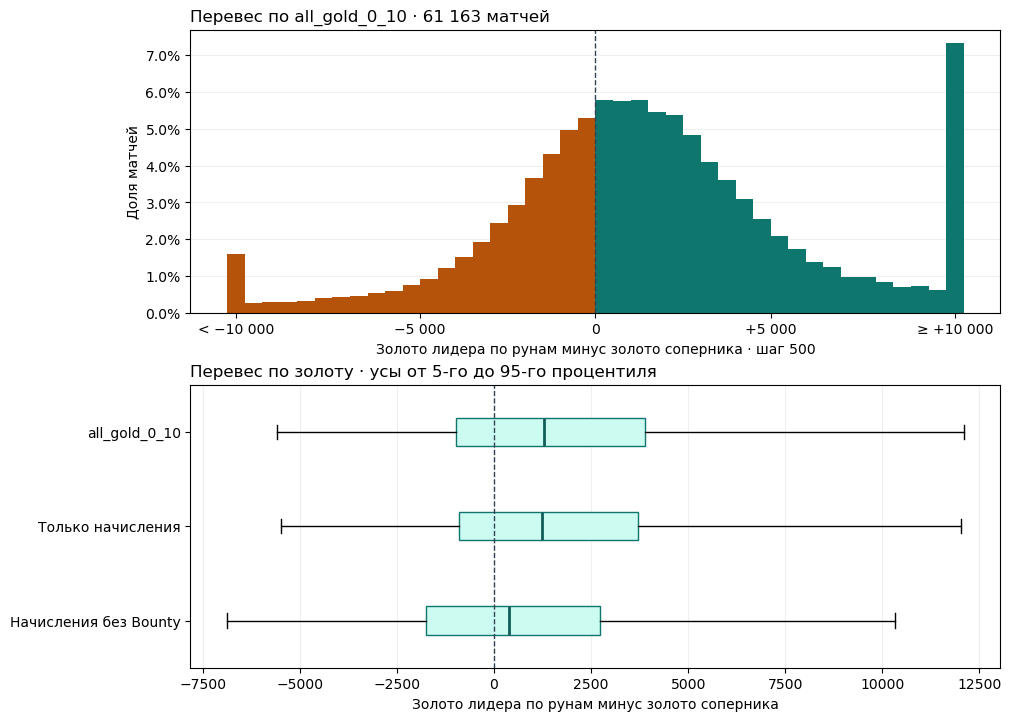

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pyspark import StorageLevel

from lakehouse_spark import SparkSessionContext

with SparkSessionContext("bounty-recorded-gold-10") as spark:
    scored = spark.sql("""
        WITH matches AS (
            SELECT match_id
            FROM lakehouse.raw.pg__matches
            WHERE match_id IS NOT NULL
            GROUP BY match_id
            HAVING MIN(duration) >= 600
        ),
        teams AS (
            SELECT match_id, account_id, MIN(CAST(is_radiant AS INT)) AS side
            FROM lakehouse.raw.pg__match_players
            WHERE match_id IS NOT NULL AND account_id > 0 AND account_id <> 4294967295
            GROUP BY match_id, account_id
            HAVING MIN(player_slot) = MAX(player_slot)
               AND MIN(CAST(is_radiant AS INT)) = MAX(CAST(is_radiant AS INT))
               AND COUNT(player_slot) = COUNT(*) AND COUNT(is_radiant) = COUNT(*)
        ),
        pickups AS (
            SELECT DISTINCT match_id, id, steam_account_id, time
            FROM lakehouse.raw.mongo__rune_events
            WHERE match_id IS NOT NULL AND rune = 'BOUNTY' AND action = 'PICKUP'
              AND time >= 0 AND time < 600
        ),
        rune_counts AS (
            SELECT r.match_id, COUNT(*) AS total_runes,
                   COUNT_IF(t.side = 1) AS radiant_runes,
                   COUNT_IF(t.side = 0) AS dire_runes
            FROM pickups r
            LEFT JOIN teams t ON r.match_id = t.match_id AND r.steam_account_id = t.account_id
            GROUP BY r.match_id
        ),
        qualified AS (
            SELECT r.match_id, r.total_runes,
                   CASE WHEN r.radiant_runes > r.dire_runes THEN 1 ELSE 0 END AS leader_side,
                   10 * GREATEST(r.radiant_runes, r.dire_runes) >= 7 * r.total_runes AS meets_70,
                   CASE WHEN r.total_runes = 8 AND r.radiant_runes + r.dire_runes = 8 THEN
                       CASE WHEN GREATEST(r.radiant_runes, r.dire_runes) = 5 THEN '5 из 8'
                            WHEN GREATEST(r.radiant_runes, r.dire_runes) >= 6 THEN '6–8 из 8' END
                   END AS comparison_group
            FROM rune_counts r JOIN matches m ON r.match_id = m.match_id
        ),
        eligible AS (
            SELECT *
            FROM qualified
            WHERE meets_70 OR comparison_group IS NOT NULL
        ),
        gold_events AS (
            SELECT DISTINCT g.match_id, g.id, g.steam_account_id, g.time, g.amount, g.reason
            FROM lakehouse.raw.mongo__gold_events g
            LEFT SEMI JOIN eligible q ON g.match_id = q.match_id
            WHERE g.time >= 0 AND g.time < 600 AND (g.amount <> 0 OR g.amount IS NULL)
        ),
        by_account AS (
            SELECT match_id, steam_account_id,
                   COUNT(*) AS events,
                   COUNT_IF(amount IS NULL) AS null_amounts,
                   COUNT_IF(amount > 0 AND reason IS NULL) AS unknown_reasons,
                   COUNT_IF(amount > 0) AS credits,
                   SUM(CASE WHEN amount > 0 THEN amount ELSE 0 END) AS gross,
                   SUM(CASE WHEN amount > 0 AND reason <> 'BOUNTY' THEN amount ELSE 0 END)
                       AS gross_without_bounty,
                   SUM(amount) AS net
            FROM gold_events
            GROUP BY match_id, steam_account_id
        ),
        by_match AS (
            SELECT g.match_id,
                   SUM(CASE WHEN t.side IS NULL THEN g.events ELSE 0 END) AS unmapped,
                   SUM(g.null_amounts) AS null_amounts,
                   SUM(g.unknown_reasons) AS unknown_reasons,
                   SUM(CASE WHEN t.side = 1 THEN g.credits ELSE 0 END) AS radiant_credits,
                   SUM(CASE WHEN t.side = 0 THEN g.credits ELSE 0 END) AS dire_credits,
                   SUM(CASE WHEN t.side = 1 THEN g.gross WHEN t.side = 0 THEN -g.gross END)
                       AS radiant_gross_diff,
                   SUM(CASE WHEN t.side = 1 THEN g.gross_without_bounty
                            WHEN t.side = 0 THEN -g.gross_without_bounty END)
                       AS radiant_without_bounty_diff,
                   SUM(CASE WHEN t.side = 1 THEN g.net WHEN t.side = 0 THEN -g.net END)
                       AS radiant_net_diff
            FROM by_account g
            LEFT JOIN teams t ON g.match_id = t.match_id AND g.steam_account_id = t.account_id
            GROUP BY g.match_id
        ),
        scored AS (
            SELECT q.match_id, q.total_runes, q.leader_side, q.meets_70, q.comparison_group,
                   g.unknown_reasons,
                   CASE WHEN g.match_id IS NULL THEN 'no_gold_events'
                        WHEN g.null_amounts > 0 THEN 'missing_amount'
                        WHEN g.unmapped > 0 THEN 'unmapped_gold'
                        WHEN g.radiant_credits = 0 OR g.dire_credits = 0 THEN 'missing_team_credits'
                        ELSE 'usable' END AS status,
                   (2 * q.leader_side - 1) * g.radiant_gross_diff AS gross_diff,
                   (2 * q.leader_side - 1) * g.radiant_without_bounty_diff AS without_bounty_diff,
                   (2 * q.leader_side - 1) * g.radiant_net_diff AS net_diff
            FROM eligible q LEFT JOIN by_match g ON q.match_id = g.match_id
        )
        SELECT * FROM scored
    """).persist(StorageLevel.DISK_ONLY)
    try:
        scored.createOrReplaceTempView("bounty_scored_for_report")
        summary = spark.sql("""
            WITH metrics AS (
            SELECT total_runes, leader_side, status, metric, diff
            FROM bounty_scored_for_report
            LATERAL VIEW STACK(
                4, 'quality', CAST(NULL AS BIGINT),
                   'gross', CASE WHEN status = 'usable' THEN gross_diff END,
                   'gross_without_bounty', CASE WHEN status = 'usable' AND unknown_reasons = 0
                                                THEN without_bounty_diff END,
                   'all_gold_0_10', CASE WHEN status = 'usable' THEN net_diff END
            ) outcomes AS metric, diff
            WHERE meets_70 AND (metric = 'quality' OR diff IS NOT NULL)
        ),
        report_rows AS (
            SELECT metric, status, diff, pickup_count, leader, bin_start
            FROM metrics
            LATERAL VIEW STACK(
                4, 'all_pickup_counts', 'both', CAST(NULL AS INT),
                   'all_pickup_counts', CASE WHEN leader_side = 1 THEN 'Radiant' ELSE 'Dire' END,
                       CAST(NULL AS INT),
                   '8', CASE WHEN total_runes = 8 THEN 'both' END, CAST(NULL AS INT),
                   'all_pickup_counts', CASE WHEN metric = 'all_gold_0_10' THEN 'both' END,
                       CAST(500 * FLOOR(LEAST(10000, GREATEST(-10500, diff)) / 500) AS INT)
            ) cohorts AS pickup_count, leader, bin_start
            WHERE leader IS NOT NULL
        )
        SELECT CASE WHEN bin_start IS NOT NULL THEN 'histogram'
                    WHEN metric = 'quality' THEN 'quality' ELSE 'result' END AS section,
               metric,
               pickup_count, leader, bin_start,
               status, COUNT(*) AS matches,
               CASE WHEN metric <> 'quality' THEN COUNT_IF(diff > 0) END AS ahead,
               CASE WHEN metric <> 'quality' THEN COUNT_IF(diff = 0) END AS tied,
               ROUND(100.0 * AVG(CASE WHEN diff IS NOT NULL
                                     THEN CAST(diff > 0 AS INT) END), 2) AS pct_ahead,
               ROUND(AVG(diff), 1) AS mean_diff,
               CASE WHEN bin_start IS NULL AND metric <> 'quality' THEN
                   PERCENTILE_APPROX(diff, ARRAY(0.05, 0.25, 0.50, 0.75, 0.95))
               END AS p05_q25_median_q75_p95
        FROM report_rows
        GROUP BY metric, status, pickup_count, leader, bin_start
        """).collect()

        quartiles = next((
            row["p05_q25_median_q75_p95"] for row in summary
            if row["section"] == "result" and row["metric"] == "all_gold_0_10"
            and row["pickup_count"] == "all_pickup_counts" and row["leader"] == "both"
        ), None)
        if quartiles is None:
            print("Нет пригодных матчей для проверки выбросов.")
        else:
            q1, q3 = quartiles[1], quartiles[3]
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            print(f"Границы выбросов по all_gold_0_10: {lower:,.1f} и {upper:,.1f}")
            # Границы вычислены из целочисленных квартилей и кратны 0,5.
            scored.sparkSession.sql(f"""
                SELECT cohort, COUNT(*) AS matches,
                       COUNT(DISTINCT match_id) AS unique_match_ids,
                       ROUND(100 * AVG(CAST(net_diff > 0 AS INT)), 2) AS pct_ahead,
                       ROUND(AVG(net_diff), 1) AS mean_diff,
                       PERCENTILE_APPROX(net_diff, 0.5) AS median_diff
                FROM bounty_scored_for_report
                LATERAL VIEW STACK(2, 'Все',
                    CASE WHEN net_diff < {lower:.1f} OR net_diff > {upper:.1f}
                         THEN 'Выбросы' ELSE 'Без выбросов' END) labels AS cohort
                WHERE meets_70 AND status = 'usable' AND net_diff IS NOT NULL
                GROUP BY cohort
                ORDER BY cohort
            """).show(truncate=False)
        print("\nСравнение при ровно 8 подборах с известной стороной")
        spark.sql("""
            WITH sides AS (
                SELECT match_id, comparison_group, net_diff,
                       CASE WHEN leader_side = 1 THEN 'Radiant' ELSE 'Dire' END AS side
                FROM bounty_scored_for_report
                WHERE comparison_group IS NOT NULL AND status = 'usable'
                  AND net_diff IS NOT NULL
            )
            SELECT comparison_group, leader,
                   COUNT(*) AS matches,
                   COUNT(DISTINCT match_id) AS unique_match_ids,
                   COUNT_IF(net_diff > 0) AS ahead,
                   ROUND(100 * AVG(CAST(net_diff > 0 AS INT)), 2) AS pct_ahead,
                   PERCENTILE_APPROX(net_diff, 0.5) AS median_diff
            FROM sides
            LATERAL VIEW STACK(2, side, 'Все') labels AS leader
            GROUP BY comparison_group, leader
            ORDER BY leader, comparison_group
        """).show(truncate=False)
    finally:
        scored.sparkSession.catalog.dropTempView("bounty_scored_for_report")
        scored.unpersist()


columns = ("section", "metric", "pickup_count", "leader", "status", "matches",
           "ahead", "tied", "pct_ahead", "mean_diff", "p05_q25_median_q75_p95")
report = sorted((r for r in summary if r["section"] != "histogram"),
                key=lambda r: tuple(r[k] for k in columns[:5]))
print(" | ".join(columns))
for row in report:
    print(" | ".join("—" if row[key] is None else str(row[key]) for key in columns))

bins = {r["bin_start"]: r["matches"] for r in summary if r["section"] == "histogram"}
metrics = (
    ("all_gold_0_10", "all_gold_0_10"),
    ("gross", "Только начисления"),
    ("gross_without_bounty", "Начисления без Bounty"),
)
if bins:
    rows = {r["metric"]: r for r in report if r["section"] == "result"
            and r["pickup_count"] == "all_pickup_counts" and r["leader"] == "both"}
    total = sum(bins.values())
    assert total == rows["all_gold_0_10"]["matches"]
    fig, (hist, box) = plt.subplots(2, 1, figsize=(10, 7.1), layout="constrained")
    starts = list(range(-10500, 10001, 500))
    hist.bar(starts, [100 * bins.get(x, 0) / total for x in starts],
             width=500, align="edge",
             color=["#b45309" if x < 0 else "#0f766e" for x in starts])
    hist.set_xticks([-10250, -5000, 0, 5000, 10250],
                    ["< −10 000", "−5 000", "0", "+5 000", "≥ +10 000"])
    hist.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    hist.set_ylabel("Доля матчей")
    hist.set_title(f"Перевес по all_gold_0_10 · {total:,} матчей".replace(",", " "), loc="left")
    hist.set_xlabel("Золото лидера по рунам минус золото соперника · шаг 500")
    hist.grid(axis="y", alpha=0.2)
    stats = []
    for metric, label in metrics:
        if metric in rows:
            low, q1, median, q3, high = rows[metric]["p05_q25_median_q75_p95"]
            stats.append(dict(label=label, whislo=low, q1=q1, med=median, q3=q3, whishi=high))
    box.bxp(stats, vert=False, showfliers=False, patch_artist=True,
            boxprops={"facecolor": "#ccfbf1", "edgecolor": "#0f766e"},
            medianprops={"color": "#115e59", "linewidth": 2})
    box.invert_yaxis()
    box.set_title("Перевес по золоту · усы от 5-го до 95-го процентиля", loc="left")
    box.set_xlabel("Золото лидера по рунам минус золото соперника")
    box.grid(axis="x", alpha=0.2)
    for ax in (hist, box):
        ax.set_axisbelow(True)
        ax.axvline(0, color="#334155", linestyle="--", linewidth=1)
    plt.show()
else:
    print("Нет пригодных матчей для графиков.")


# Вывод
Команда, собравшая не менее 70% зарегистрированных Bounty Rune за первые 10 минут, опережала соперника по all_gold_0_10 в 64,91% из 61 110 пригодных матчей. Медианный перевес составил 1 294 золота. По положительным начислениям без наград за Bounty Rune доля составила 54,74%.

Лидер по рунам к 12:00 взял первую вражескую башню в 52,5% из 161 102 пригодных матчей. Результат различался по сторонам — 58,6% для Radiant и 47,5% для Dire. В изученной выборке контроль рун был заметнее связан с золотым перевесом, чем с первой башней.